# Join of the dastasets

In [133]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='inner', suffixes=('_hd', '_le'))
joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)

print(joined_df['subject_id'].nunique())
# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates(keep=False).reset_index(drop=True)



joined_df.dropna(subset=['valueuom'], inplace=True)
joined_df

4368


,subject_id,hadm_id,charttime_hd,icd_code,long_title,gender,age,charttime_le,valuenum,valueuom,...,charttime,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10000980,29654838,2188-01-06 03:00:00,I50,Heart failure,F,75,2188-01-04 23:43:00,198.00,IU/L,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,2188-01-06 03:00:00,I50,Heart failure,F,75,2188-01-04 23:43:00,5.00,ng/mL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,2188-01-06 03:00:00,I50,Heart failure,F,75,2188-01-04 23:43:00,0.03,ng/mL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,2188-01-06 03:00:00,I50,Heart failure,F,75,2188-01-05 06:56:00,85.80,sec,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,10000980,29654838,2188-01-06 03:00:00,I50,Heart failure,F,75,2188-01-05 06:56:00,20.00,mEq/L,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4418062,19998600,21593455,2155-11-27 03:00:00,I35,Nonrheumatic aortic valve disorders,F,83,2155-11-27 10:00:00,2.00,ng/mL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4418063,19998600,21593455,2155-11-27 03:00:00,I35,Nonrheumatic aortic valve disorders,F,83,2155-11-27 10:00:00,143.00,mg/dL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4418064,19998600,21593455,2155-11-27 03:00:00,I35,Nonrheumatic aortic valve disorders,F,83,2155-11-27 10:00:00,3.90,mEq/L,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4418065,19998600,21593455,2155-11-27 03:00:00,I35,Nonrheumatic aortic valve disorders,F,83,2155-11-27 10:00:00,141.00,mEq/L,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Correlation between the cols

In [134]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("pearson")

,age,valuenum,dilution_value
age,1.000000,-0.000469,0.049110
valuenum,-0.000469,1.000000,-0.001436
dilution_value,0.049110,-0.001436,1.000000


In [135]:
# Kendall correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("kendall")

,age,valuenum,dilution_value
age,1.000000,0.003420,0.101481
valuenum,0.003420,1.000000,-0.000095
dilution_value,0.101481,-0.000095,1.000000


In [136]:
# Spearman correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("spearman")

,age,valuenum,dilution_value
age,1.000000,0.004730,0.128116
valuenum,0.004730,1.000000,-0.000144
dilution_value,0.128116,-0.000144,1.000000


In [137]:
# Abnormal flag ratio
abnormal_ratio = (
    joined_df
    .groupby(['subject_id', 'hadm_id'], as_index=False)['flag']
    .mean()
    .rename(columns={'flag': 'abnormal_flag_ratio'})
)
joined_df = joined_df.merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')

In [138]:
# Number of unique fluid types with abnormal results per admission
abnormal_mask = joined_df['flag'] == 1
fluid_abnormal = joined_df[abnormal_mask].groupby(['subject_id', 'hadm_id']).agg(
    abnormal_fluid_count=('fluid', 'nunique'),
    fluids_analyzed=('fluid', lambda x: ', '.join(x.unique()))
).reset_index()

# Add the columns to the joined_df
joined_df = joined_df.merge(fluid_abnormal, on=['subject_id', 'hadm_id'], how='left')

In [139]:
# Number of laboratory events per hadm_id
lab_events_count = joined_df.groupby('hadm_id').size()
lab_events_count

hadm_id
20004456      65
20007905    2580
20013519      63
20013602     144
20014999     160
            ... 
29991470      42
29995484     224
29996728     310
29998994      39
29999670     126
Length: 4733, dtype: int64

## Patient risk profile

In [140]:
# Build patient-level aggregates
base = joined_df[['subject_id', 'hadm_id', 'age', 'icd_code']]

org_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['org_name']
    .nunique()
    .reset_index(name='unique_organisms_count')
)

ab_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['ab_name']
    .nunique()
    .reset_index(name='unique_antibiotics_count')
)

resistance_stats = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby(['subject_id', 'hadm_id'], as_index=False)
    .agg(
        resistant_organism_count=('org_name', 'nunique'),
        resistant_antibiotic_count=('ab_name', 'nunique')
    )
)

abnormal_ratio = (
    joined_df.groupby(['subject_id', 'hadm_id'])['flag']
    .mean()
    .reset_index(name='abnormal_flag_ratio')
)

abnormal_fluids = (
    joined_df[joined_df['flag'] == 1]
    .groupby(['subject_id', 'hadm_id'])
    .agg(
        abnormal_fluid_count=('fluid', 'nunique'),
        fluids_analyzed=('fluid', lambda x: ', '.join(sorted(x.unique())))
    )
    .reset_index()
)

# Assemble risk profile
risk_profile = (
    base.merge(org_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(ab_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(resistance_stats, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_fluids, on=['subject_id', 'hadm_id'], how='left')
)


risk_profile = risk_profile.drop_duplicates(['subject_id', 'hadm_id'])
risk_profile.to_csv("../../data/profiles/risk_profile.csv")

risk_profile

,subject_id,hadm_id,age,icd_code,unique_organisms_count,unique_antibiotics_count,resistant_organism_count,resistant_antibiotic_count,abnormal_flag_ratio,abnormal_fluid_count,fluids_analyzed
0,10000980,29654838,75,I50,0,0,NaN,NaN,0.386364,1.0,Blood
44,10000980,26913865,75,I21,0,0,NaN,NaN,0.396694,1.0,Blood
165,10002013,24760295,69,I21,0,0,NaN,NaN,0.384615,1.0,Blood
204,10002155,23822395,69,I21,0,0,NaN,NaN,0.368821,1.0,Blood
3360,10004457,28723315,66,I35,0,0,NaN,NaN,0.285714,1.0,Blood
...,...,...,...,...,...,...,...,...,...,...,...
4289351,19998596,24860241,71,I48,0,0,NaN,NaN,0.508772,1.0,Blood
4289465,19998597,23720781,57,I31,0,0,NaN,NaN,0.564815,1.0,Blood
4289573,19998598,26940500,69,I47,0,0,NaN,NaN,0.256410,1.0,Blood
4289612,19998599,20343031,59,I30,0,0,NaN,NaN,0.490909,1.0,Blood


## Treatment Response Profiles

In [141]:
intermediate_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'I']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

resistant_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

sensitive_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'S']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

treatment_profile = (
    joined_df[
        joined_df['ab_name'].notna() & joined_df['interpretation'].notna()
    ]
    .groupby(['subject_id', 'hadm_id', 'interpretation'])
    .agg(
        organism_count=('org_name', 'nunique'),
        antibiotic_count=('ab_name', 'nunique')
    )
    .unstack(fill_value=0)
)

treatment_profile.columns = [
    f"{metric}_{label.lower()}"
    for metric, label in treatment_profile.columns
]

treatment_profile = treatment_profile.reset_index()
treatment_profile.to_csv("../../data/profiles/treatment_profile.csv")
treatment_profile


,subject_id,hadm_id,organism_count_i,organism_count_r,organism_count_s,antibiotic_count_i,antibiotic_count_r,antibiotic_count_s
0,10104308,24307783,0,1,1,0,1,10
1,10108435,23333218,0,1,1,0,4,5
2,10109085,25661234,0,1,1,0,1,9
3,10124346,24026336,0,1,1,0,1,12
4,10169726,22012406,0,0,1,0,0,7
...,...,...,...,...,...,...,...,...
379,19961611,25180816,0,0,1,0,0,6
380,19966553,27576329,0,1,1,0,3,6
381,19990821,27777812,0,1,1,0,1,6
382,19992875,20870047,0,0,1,0,0,1


## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

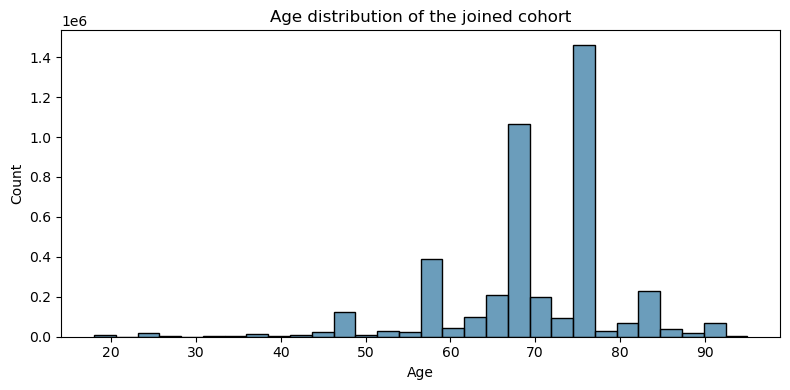

In [142]:
plt.figure(figsize=(8, 4))
sns.histplot(joined_df['age'].dropna(), bins=30, color='#3A7CA5')
plt.title('Age distribution of the joined cohort')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()